# Detección de exoplanetas con IA
## Fases 1 y 2 de CRISP-ML(Q): comprensión del problema y preparación de datos

**Dataset:** [Kepler Labelled Time Series Data](https://www.kaggle.com/datasets/keplersmachines/kepler-labelled-time-series-data) (NASA, telescopio Kepler)

| Fase | Fecha | Contenido |
|---|---|---|
| 1. Comprensión del negocio y de los datos | 10 nov | Ficha del problema, criterios de éxito, análisis exploratorio |
| 2. Preparación de datos | 11 – 13 nov | Limpieza, normalización, transformada de Fourier, balanceo |

# Fase 1 — Comprensión del negocio y de los datos (10 nov)

## 1.1 Ficha del problema

| Punto | Definición |
|---|---|
| **Problema** | Los telescopios generan miles de curvas de luz y revisarlas a mano no es viable. |
| **Objetivo** | Predecir si una estrella tiene un exoplaneta a partir de su curva de luz. |
| **Tipo de tarea** | Aprendizaje supervisado, **clasificación binaria** (1 = tiene planeta, 0 = no tiene). |
| **Idea física** | Cuando un planeta pasa delante de su estrella, el brillo baja un poco y de forma periódica (método de tránsito). |
| **Criterios de éxito** | En el conjunto de prueba, para la clase "con planeta": **recall ≥ 0,8** y **F1 ≥ 0,6**. |
| **Métricas** | Recall, precisión, F1 y matriz de confusión. No se usa accuracy porque las clases están muy desbalanceadas. |
| **Uso final** | El modelo se expondrá en una API REST que recibe una curva de luz y devuelve la predicción. |

## 1.2 Carga de datos

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
np.random.seed(42)

# En Google Colab se descarga directo desde Kaggle con kagglehub.
# Si ya tienes los CSV, define la variable KEPLER_DIR con la carpeta donde están.
DATA_DIR = os.environ.get('KEPLER_DIR')
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('keplersmachines/kepler-labelled-time-series-data')

train = pd.read_csv(os.path.join(DATA_DIR, 'exoTrain.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'exoTest.csv'))
print('Entrenamiento:', train.shape)
print('Prueba:       ', test.shape)

Entrenamiento: (5087, 3198)
Prueba:        (570, 3198)


## 1.3 Estructura del dataset

In [2]:
train.iloc[:5, :8]

,LABEL,FLUX.1,FLUX.2,FLUX.3,FLUX.4,FLUX.5,FLUX.6,FLUX.7
0,2,93.85,83.81,20.10,-26.98,-39.56,-124.71,-135.18
1,2,-38.88,-33.83,-58.54,-40.09,-79.31,-72.81,-86.55
2,2,532.64,535.92,513.73,496.92,456.45,466.00,464.50
3,2,326.52,347.39,302.35,298.13,317.74,312.70,322.33
4,2,-1107.21,-1112.59,-1118.95,-1095.10,-1057.55,-1034.48,-998.34


In [3]:
print('Tipos de datos:', train.dtypes.value_counts().to_dict())
print('Valores faltantes  -> entrenamiento:', int(train.isna().sum().sum()), '| prueba:', int(test.isna().sum().sum()))
print('Filas duplicadas   -> entrenamiento:', int(train.duplicated().sum()), '| prueba:', int(test.duplicated().sum()))

Tipos de datos: {dtype('float64'): 3197, dtype('int64'): 1}
Valores faltantes  -> entrenamiento: 0 | prueba: 0


Filas duplicadas   -> entrenamiento: 0 | prueba: 0


- **LABEL** es la variable objetivo: 2 = la estrella tiene al menos un exoplaneta confirmado, 1 = no tiene.
- **FLUX.1 a FLUX.3197** son 3.197 mediciones del brillo (flujo de luz) de la estrella en el tiempo. Leídas en orden forman su **curva de luz**.
- Cada fila es una estrella. No hay valores faltantes ni filas duplicadas.

## 1.4 Variable objetivo: desbalance de clases

In [4]:
conteo = pd.DataFrame({
    'Entrenamiento': train['LABEL'].value_counts().sort_index(),
    'Prueba': test['LABEL'].value_counts().sort_index()})
conteo.index = ['Sin planeta (1)', 'Con planeta (2)']
print((conteo.loc['Con planeta (2)'] / conteo.sum() * 100).round(2).rename('% con planeta').to_string())
conteo

Entrenamiento    0.73
Prueba           0.88


,Entrenamiento,Prueba
Sin planeta (1),5050,565
Con planeta (2),37,5


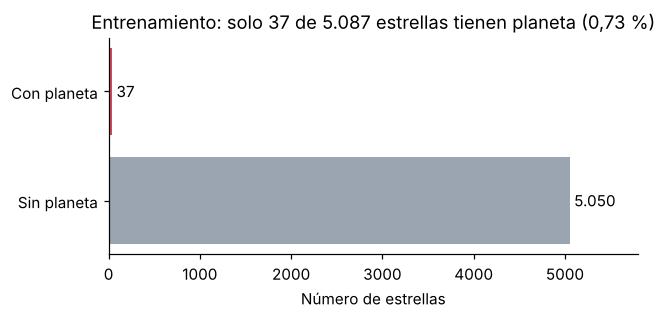

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
vals = train['LABEL'].value_counts().sort_index()
ax.barh(['Sin planeta', 'Con planeta'], vals.values, color=['#9aa5b1', '#d1495b'])
for i, v in enumerate(vals.values):
    ax.text(v + 50, i, f'{v:,}'.replace(',', '.'), va='center')
ax.set_title('Entrenamiento: solo 37 de 5.087 estrellas tienen planeta (0,73 %)')
ax.set_xlim(0, 5800); ax.set_xlabel('Número de estrellas')
plt.tight_layout(); plt.show()

In [6]:
pos = np.where(train['LABEL'] == 2)[0]
print('Posiciones de las estrellas con planeta en exoTrain:', pos.min(), 'a', pos.max())

Posiciones de las estrellas con planeta en exoTrain: 0 a 36


**Hallazgos:**
- El desbalance es extremo: un modelo que diga siempre "sin planeta" tendría **99,3 % de accuracy** y no encontraría ningún planeta. Por eso se evalúa con recall, precisión y F1.
- Las 37 estrellas con planeta están **todas al inicio del archivo** (filas 0 a 36). Al hacer validación cruzada hay que **mezclar y estratificar** las filas; si no, algunos pliegues quedarían sin ningún planeta.

## 1.5 Curvas de luz: con planeta vs. sin planeta

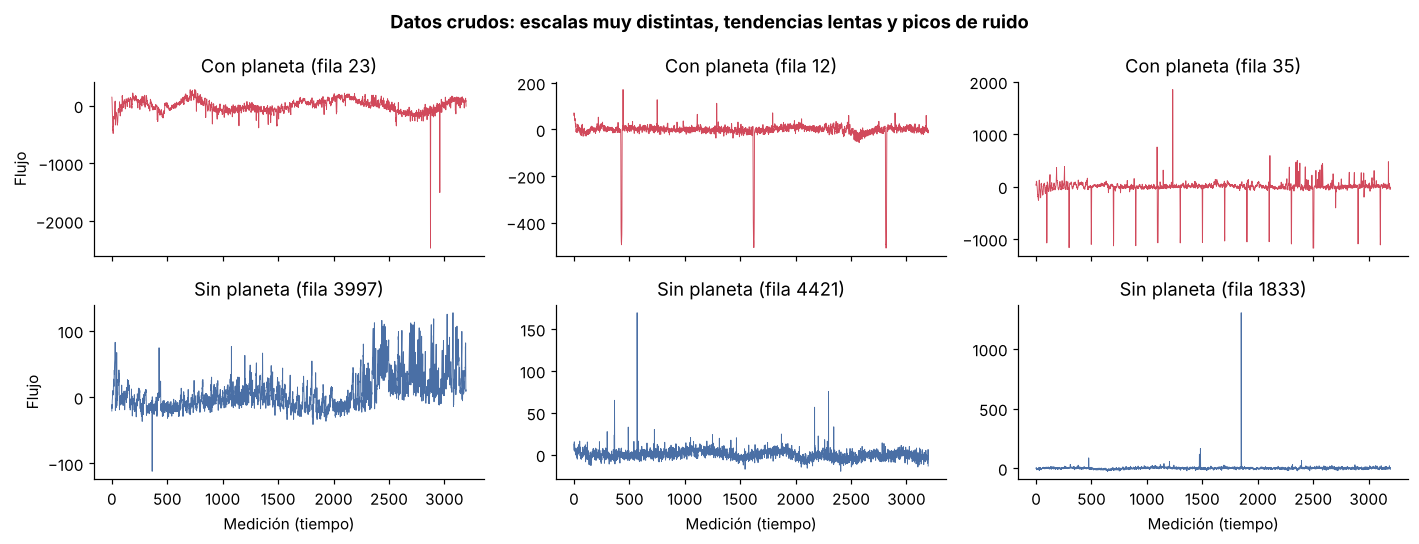

In [7]:
flux_cols = [c for c in train.columns if c.startswith('FLUX')]
t = np.arange(len(flux_cols))
con = [23, 12, 35]   # tres estrellas con planeta con caídas claras
sin = train[train.LABEL == 1].sample(3, random_state=1).index

fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True)
for ax, i in zip(axes[0], con):
    ax.plot(t, train.loc[i, flux_cols], lw=0.6, color='#d1495b'); ax.set_title(f'Con planeta (fila {i})')
for ax, i in zip(axes[1], sin):
    ax.plot(t, train.loc[i, flux_cols], lw=0.6, color='#4a6fa5'); ax.set_title(f'Sin planeta (fila {i})')
for ax in axes[:, 0]: ax.set_ylabel('Flujo')
for ax in axes[1]: ax.set_xlabel('Medición (tiempo)')
fig.suptitle('Datos crudos: escalas muy distintas, tendencias lentas y picos de ruido', fontweight='bold')
plt.tight_layout(); plt.show()

En las estrellas con planeta se ven **caídas de brillo** (los tránsitos), pero mezcladas con **tendencias lentas** propias de cada estrella. En las estrellas sin planeta aparecen **picos de ruido hacia arriba**. Además, cada curva tiene una escala distinta. Todo esto justifica la limpieza de la fase 2.

## 1.6 Escala de las curvas

Valor mínimo global: -2,385,019   Valor máximo global: 4,299,288


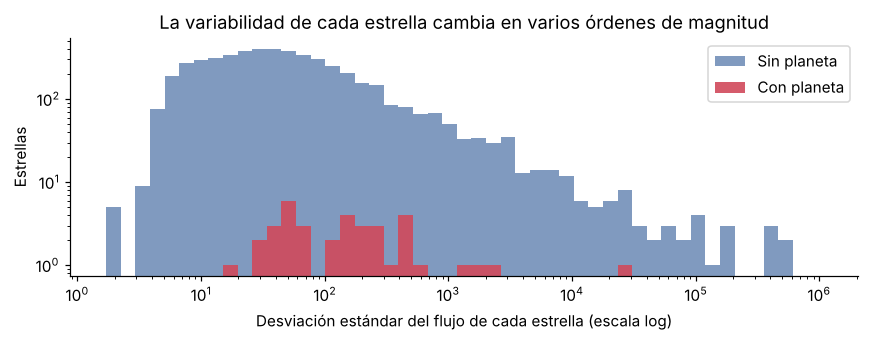

In [8]:
X_raw = train[flux_cols].values
y_raw = train['LABEL'].values
desv = X_raw.std(axis=1)
print(f'Valor mínimo global: {X_raw.min():,.0f}   Valor máximo global: {X_raw.max():,.0f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(np.log10(desv.min()), np.log10(desv.max()), 50)
ax.hist(desv[y_raw == 1], bins=bins, alpha=0.7, label='Sin planeta', color='#4a6fa5')
ax.hist(desv[y_raw == 2], bins=bins, alpha=0.9, label='Con planeta', color='#d1495b')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Desviación estándar del flujo de cada estrella (escala log)'); ax.set_ylabel('Estrellas')
ax.set_title('La variabilidad de cada estrella cambia en varios órdenes de magnitud')
ax.legend(); plt.tight_layout(); plt.show()

Cada estrella tiene su propio nivel de brillo y de variación. Si no se normaliza **cada curva por separado**, el modelo aprendería el tamaño de los números y no la **forma** de la curva.

## 1.7 Valores atípicos

In [9]:
Z = (X_raw - X_raw.mean(1, keepdims=True)) / X_raw.std(1, keepdims=True)
print(f'Puntos a más de 3 desviaciones por ENCIMA de la media: {(Z > 3).mean()*100:.2f} %')
print(f'Puntos a más de 3 desviaciones por DEBAJO de la media: {(Z < -3).mean()*100:.2f} %')
print('Estrellas con al menos un pico por encima de 5 desviaciones:', int((Z.max(1) > 5).sum()))

Puntos a más de 3 desviaciones por ENCIMA de la media: 0.53 %
Puntos a más de 3 desviaciones por DEBAJO de la media: 0.35 %
Estrellas con al menos un pico por encima de 5 desviaciones: 4096


Los tránsitos son **caídas** de brillo, así que los picos **hacia arriba** se pueden tratar como ruido del sensor (rayos cósmicos, errores de medición) y recortarse sin perder información útil.

## 1.8 Conclusiones y control de calidad de la fase 1

| Verificación | Resultado |
|---|---|
| ¿Los datos están etiquetados para aprendizaje supervisado? | Sí, columna LABEL en entrenamiento y prueba |
| ¿Hay faltantes o duplicados? | No |
| ¿Hay suficientes datos? | 5.087 estrellas de entrenamiento y 570 de prueba, con 3.197 mediciones cada una |
| Riesgo principal | Desbalance extremo (0,73 %): se usarán recall/F1, validación estratificada y SMOTE |
| Otros riesgos | Escalas distintas entre estrellas, tendencias lentas y picos de ruido: se tratan en la fase 2 |

**Decisión:** los datos permiten resolver el problema, así que se pasa a la fase 2.

# Fase 2 — Preparación de datos (11 – 13 nov)

Todas las transformaciones se aplican **a cada estrella por separado** y no aprenden parámetros del conjunto de datos. Así se pueden aplicar igual al conjunto de prueba y, más adelante, a cada curva que llegue por la API, **sin fuga de datos**. La única excepción es SMOTE, que se aplica solo al entrenamiento.

## 2.1 Recodificar la etiqueta

In [10]:
X_train = train[flux_cols].values.astype(np.float64)
X_test  = test[flux_cols].values.astype(np.float64)
y_train = (train['LABEL'].values == 2).astype(int)   # 1 = con planeta, 0 = sin planeta
y_test  = (test['LABEL'].values == 2).astype(int)
print('y_train:', np.bincount(y_train), '| y_test:', np.bincount(y_test))

y_train: [5050   37] | y_test: [565   5]


## 2.2 Pipeline de limpieza

1. **Normalizar** cada curva (media 0, desviación 1).
2. **Recortar los picos hacia arriba** por encima de 3 desviaciones.
3. **Quitar la tendencia**: restar una mediana móvil de 101 puntos, que elimina las variaciones lentas propias de la estrella y deja las caídas cortas de los tránsitos.
4. **Suavizar** con un filtro gaussiano (σ = 2) para reducir el ruido de alta frecuencia.
5. **Volver a normalizar** la curva limpia.

In [11]:
from scipy.ndimage import median_filter, gaussian_filter1d

def limpiar_curvas(X, recorte=3.0, ventana=101, sigma=2):
    """Limpia un arreglo (n_estrellas, 3197). Cada fila se procesa por separado."""
    X = np.asarray(X, dtype=np.float64)
    Z = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)   # 1. normalizar
    Z = np.minimum(Z, recorte)                                             # 2. recortar picos hacia arriba
    Z = Z - median_filter(Z, size=(1, ventana), mode='nearest')            # 3. quitar tendencia
    Z = gaussian_filter1d(Z, sigma=sigma, axis=1)                          # 4. suavizar
    Z = (Z - Z.mean(1, keepdims=True)) / (Z.std(1, keepdims=True) + 1e-8) # 5. normalizar de nuevo
    return Z.astype(np.float32)

Z_train = limpiar_curvas(X_train)
Z_test  = limpiar_curvas(X_test)
print('Curvas limpias:', Z_train.shape, Z_test.shape)

Curvas limpias: (5087, 3197) (570, 3197)


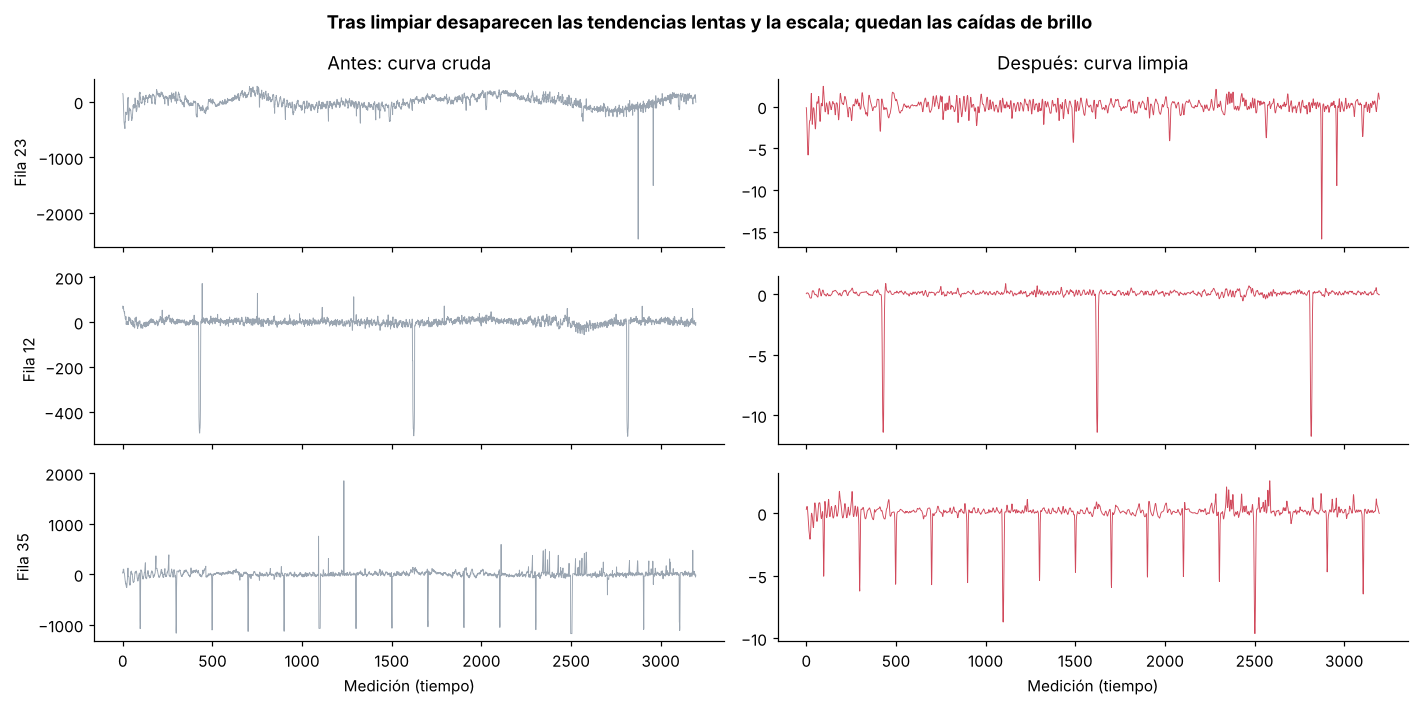

In [12]:
fig, axes = plt.subplots(len(con), 2, figsize=(13, 6.5), sharex=True)
for row, i in enumerate(con):
    axes[row, 0].plot(t, X_train[i], lw=0.6, color='#9aa5b1'); axes[row, 0].set_ylabel(f'Fila {i}')
    axes[row, 1].plot(t, Z_train[i], lw=0.6, color='#d1495b')
axes[0, 0].set_title('Antes: curva cruda'); axes[0, 1].set_title('Después: curva limpia')
for ax in axes[-1]: ax.set_xlabel('Medición (tiempo)')
fig.suptitle('Tras limpiar desaparecen las tendencias lentas y la escala; quedan las caídas de brillo', fontweight='bold')
plt.tight_layout(); plt.show()

## 2.3 Transformada de Fourier

La transformada rápida de Fourier (FFT) pasa la curva del **dominio del tiempo** al de la **frecuencia**. Como un planeta pasa delante de su estrella cada cierto tiempo fijo, esa repetición aparece como **picos en frecuencias concretas**, mientras que el ruido queda disperso. Se usa la magnitud del espectro (1.598 frecuencias), sin la componente constante, normalizada por estrella.

In [13]:
def espectro_fourier(Z):
    F = np.abs(np.fft.rfft(Z, axis=1))[:, 1:]          # magnitud, sin componente constante
    return (F / (F.max(1, keepdims=True) + 1e-8)).astype(np.float32)

F_train = espectro_fourier(Z_train)
F_test  = espectro_fourier(Z_test)
print('Características de Fourier:', F_train.shape, F_test.shape)

Características de Fourier: (5087, 1598) (570, 1598)


Estrellas con un pico fuerte (> 0,5) en esa banda -> con planeta: 16 de 37 (43 %) | sin planeta: 4.2 %


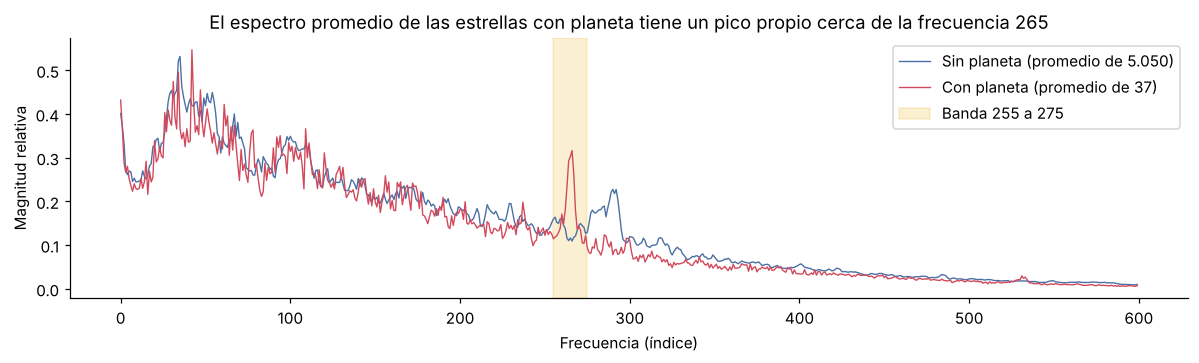

In [14]:
banda = slice(255, 275)   # frecuencias donde más difieren los promedios de cada clase
pico = F_train[:, banda].max(1)
print(f'Estrellas con un pico fuerte (> 0,5) en esa banda -> con planeta: {(pico[y_train==1] > 0.5).sum()} de 37 '
      f'({(pico[y_train==1] > 0.5).mean()*100:.0f} %) | sin planeta: {(pico[y_train==0] > 0.5).mean()*100:.1f} %')

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(F_train[y_train == 0].mean(0)[:600], lw=0.9, color='#4a6fa5', label='Sin planeta (promedio de 5.050)')
ax.plot(F_train[y_train == 1].mean(0)[:600], lw=0.9, color='#d1495b', label='Con planeta (promedio de 37)')
ax.axvspan(255, 275, color='#f2c14e', alpha=0.25, label='Banda 255 a 275')
ax.set_xlabel('Frecuencia (índice)'); ax.set_ylabel('Magnitud relativa')
ax.set_title('El espectro promedio de las estrellas con planeta tiene un pico propio cerca de la frecuencia 265')
ax.legend(); plt.tight_layout(); plt.show()

El 43 % de las estrellas con planeta tiene un pico fuerte en esa banda de frecuencias, frente a solo el 4 % de las estrellas sin planeta. Es una señal útil para el modelo, aunque **no aparece en todas**: por eso se necesita un modelo que combine muchas frecuencias a la vez.

**Precaución:** según la descripción del dataset, varias estrellas con planeta vienen de otras campañas de Kepler. Parte de esta diferencia podría deberse a la campaña de observación y no al planeta. Se tendrá en cuenta al interpretar los resultados de la fase 4.

## 2.4 Balanceo de clases con SMOTE

SMOTE crea ejemplos **sintéticos** de la clase minoritaria interpolando entre estrellas con planeta parecidas. Se aplica **solo al entrenamiento**: el conjunto de prueba se queda con sus datos reales.

En la fase 3, SMOTE irá **dentro de cada pliegue** de la validación cruzada (con un `Pipeline` de imbalanced-learn), para que ninguna estrella sintética se filtre al pliegue de validación. Aquí se muestra su efecto.

In [15]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, k_neighbors=5)
F_bal, y_bal = smote.fit_resample(F_train, y_train)
pd.DataFrame({'Antes de SMOTE': np.bincount(y_train), 'Después de SMOTE': np.bincount(y_bal)},
             index=['Sin planeta (0)', 'Con planeta (1)'])

,Antes de SMOTE,Después de SMOTE
Sin planeta (0),5050,5050
Con planeta (1),37,5050


## 2.5 Control de calidad de la fase 2

In [16]:
checks = {
    'Sin valores NaN ni infinitos': all(np.isfinite(a).all() for a in [Z_train, Z_test, F_train, F_test]),
    'Mismas columnas en entrenamiento y prueba': Z_train.shape[1] == Z_test.shape[1] and F_train.shape[1] == F_test.shape[1],
    'Mismo número de filas que los datos originales': len(Z_train) == len(train) and len(Z_test) == len(test),
    'Prueba sin modificar por SMOTE (570 estrellas, 5 con planeta)': len(F_test) == 570 and y_test.sum() == 5,
    'Cada curva limpia tiene media 0 y desviación 1': np.allclose(Z_train.mean(1), 0, atol=1e-3) and np.allclose(Z_train.std(1), 1, atol=1e-2),
}
for k, v in checks.items():
    print(('OK   ' if v else 'FALLA'), k)
assert all(checks.values())

OK    Sin valores NaN ni infinitos
OK    Mismas columnas en entrenamiento y prueba
OK    Mismo número de filas que los datos originales
OK    Prueba sin modificar por SMOTE (570 estrellas, 5 con planeta)
OK    Cada curva limpia tiene media 0 y desviación 1


## 2.6 Guardar los datos procesados para la fase 3

In [17]:
np.savez_compressed('kepler_procesado.npz',
                    Z_train=Z_train, Z_test=Z_test, F_train=F_train, F_test=F_test,
                    y_train=y_train, y_test=y_test)
print('Guardado: kepler_procesado.npz')

Guardado: kepler_procesado.npz


**Estado al 11 de noviembre:** la fase 1 está completa y el pipeline de la fase 2 está implementado y verificado.

**Pendiente para el 12 y 13 de noviembre:**
- Revisar visualmente más estrellas para confirmar el tamaño de la ventana de la mediana móvil (101) y el suavizado (σ = 2).
- Pasar `limpiar_curvas` y `espectro_fourier` a un archivo `.py`, porque la API deberá aplicar exactamente el mismo preprocesamiento a cada curva que reciba.